# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

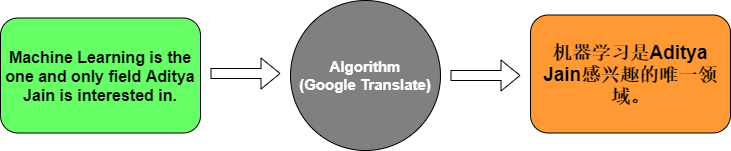

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step - accuracy: 0.0000e+00 - loss: 2.4849 - val_accuracy: 0.0000e+00 - val_loss: 2.4870
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.5714 - loss: 2.4750 - val_accuracy: 0.0000e+00 - val_loss: 2.4892
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4649 - val_accuracy: 0.0000e+00 - val_loss: 2.4916
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4541 - val_accuracy: 0.0000e+00 - val_loss: 2.4942
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.5714 - loss: 2.4422 - val_accuracy: 0.0000e+00 - val_loss: 2.4971
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5714 - loss: 2.4286 - val_accuracy: 0.0000e+00 - val_loss: 2.5004
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5714 - loss: 2.4129 - val_accuracy: 0.0000e+00 - val_loss: 2.5041
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.5714 - loss: 2.3946 - val_ac

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1. What does the Embedding layer do to a word index?**
It converts each integer word index into a dense, learnable vector (here 64 numbers). Instead of a meaningless ID, the model learns a vector that captures the word's meaning, so words used in similar contexts get similar vectors. Index 0 is reserved for padding.

**2. What is the role of the Encoder LSTM?**
It reads the English sentence word by word and updates its memory at each step. Its final hidden state is a fixed-length context vector that summarizes the meaning of the whole source sentence.

**3. What does the Decoder LSTM do?**
RepeatVector copies the context vector once for every position of the French sentence. The decoder LSTM (return_sequences=True) uses this summary to produce one output per time step, generating the French sentence one word position at a time.

**4. Why do we use softmax in the final layer?**
The Dense layer gives a raw score for every French word at every time step. Softmax turns these scores into probabilities that sum to 1, so we can pick the most likely word with argmax. It also matches the sparse_categorical_crossentropy loss.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

print("GPU:", tf.config.list_physical_devices('GPU'))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:
import kagglehub
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))
df.columns = ['english', 'french']
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
Shape: (175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [10]:
df = df.dropna().drop_duplicates()
df['english'] = df['english'].str.lower().str.strip()
df['french']  = df['french'].str.lower().str.strip()

df = df[(df['english'].str.split().str.len() <= 8) &
        (df['french'].str.split().str.len() <= 10)]

df = df.sample(n=min(30000, len(df)), random_state=42).reset_index(drop=True)
print("Pairs used:", len(df))
df.head(10)

Pairs used: 30000


,english,french
0,she waved her hand to me.,elle m'a salué de la main.
1,the red hat goes well with her dress.,le chapeau rouge est bien assorti avec sa robe.
2,she mixed him up with someone else.,elle le prit pour quelqu'un d'autre.
3,that was really bad.,c'était vraiment mauvais.
4,i would like to address two questions.,je voudrais traiter deux questions.
5,he's likely to be late.,il est probable qu'il soit en retard.
6,tom wasn't my husband at that time.,tom n'était pas mon mari à cette époque.
7,i think this will do.,je pense que cela va faire l'affaire.
8,this is your chance.,c'est ta chance.
9,please show me another one.,veuillez m'en montrer un autre.


In [11]:
english_sentences = df['english'].tolist()
french_sentences  = df['french'].tolist()

tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)

tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

eng_vocab_size = len(tokenizer_eng.word_index) + 1
frn_vocab_size = len(tokenizer_frn.word_index) + 1

eng_maxlen = max(len(s) for s in eng_sequences)
frn_maxlen = max(len(s) for s in frn_sequences)

eng_padded = pad_sequences(eng_sequences, maxlen=eng_maxlen, padding='post')
frn_padded = pad_sequences(frn_sequences, maxlen=frn_maxlen, padding='post')

print("English vocab:", eng_vocab_size, " French vocab:", frn_vocab_size)
print("Shapes:", eng_padded.shape, frn_padded.shape)

English vocab: 6986  French vocab: 12817
Shapes: (30000, 9) (30000, 13)


In [12]:
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.1, random_state=42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(eng_maxlen,)),
    tf.keras.layers.Embedding(eng_vocab_size, 128, mask_zero=True),
    tf.keras.layers.LSTM(256),
    tf.keras.layers.RepeatVector(frn_maxlen),
    tf.keras.layers.LSTM(256, return_sequences=True),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(frn_vocab_size, activation='softmax'))
])
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 9, 128)         │       894,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 13, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 13, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 13, 12817)      │     3,293,969 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,107,729 (19.48 MB)

 Trainable params: 5,107,729 (19.48 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(eng_train, np.expand_dims(frn_train, -1),
                    epochs=30, batch_size=64,
                    validation_split=0.1, callbacks=[early_stop])

Epoch 1/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.5525 - loss: 3.6948 - val_accuracy: 0.5611 - val_loss: 3.2690
Epoch 2/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.5672 - loss: 3.1565 - val_accuracy: 0.5681 - val_loss: 3.1591
Epoch 3/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.5741 - loss: 3.0653 - val_accuracy: 0.5747 - val_loss: 3.1090
Epoch 4/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.5759 - loss: 3.0184 - val_accuracy: 0.5751 - val_loss: 3.0862
Epoch 5/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.5773 - loss: 2.9734 - val_accuracy: 0.5772 - val_loss: 3.0671
Epoch 6/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - accuracy: 0.5840 - loss: 2.9046 - val_accuracy: 0.5863 - val_loss: 2.9898
Epoch 7/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.5915 - loss: 2.8232 - val_accuracy: 0.5889 - val_loss: 2.9202
Epoch 8/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 20s 46ms/step - accuracy: 0.5988 - loss: 2.7314 - 

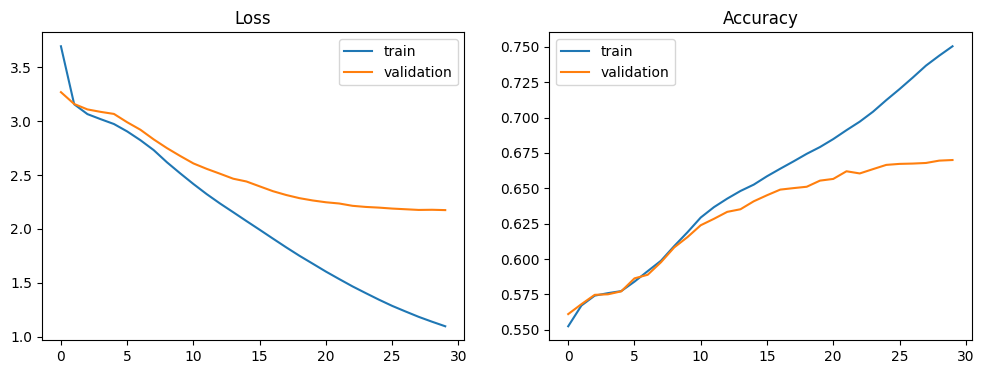

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6727 - loss: 2.1804
Test Accuracy: 0.6727


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='train')
ax[0].plot(history.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train')
ax[1].plot(history.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].legend()
plt.show()

loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f"Test Accuracy: {accuracy:.4f}")

In [15]:
def translate_sentence(sentence):
    seq = tokenizer_eng.texts_to_sequences([sentence.lower()])
    padded = pad_sequences(seq, maxlen=eng_maxlen, padding='post')
    pred = np.argmax(model.predict(padded, verbose=0), axis=-1)
    return tokenizer_frn.sequences_to_texts(pred)[0]

for i in range(5):
    eng = tokenizer_eng.sequences_to_texts([eng_test[i]])[0]
    real = tokenizer_frn.sequences_to_texts([frn_test[i]])[0]
    print(f"EN  : {eng}\nREAL: {real}\nPRED: {translate_sentence(eng)}\n")

for s in ["this is a good product", "the price is too high",
          "where is my order", "thank you very much"]:
    print(s, "->", translate_sentence(s))

EN  : can you please close the window
REAL: pouvez vous fermer la fenêtre je vous prie
PRED: peux tu me la la la la

EN  : hop in
REAL: monte
PRED: parfait 

EN  : tom is respected by everybody
REAL: tom est respecté de tous
PRED: tom est respecté le le le

EN  : he lay on his back
REAL: il était étendu sur le dos
PRED: il a à son son

EN  : why don't you just buy a new one
REAL: pourquoi n'en achètes tu pas simplement une nouvelle
PRED: pourquoi ne tu tu pas pas pas un idée

this is a good product -> c'est un bon
the price is too high -> le est est improbable
where is my order -> où est votre planète
thank you very much -> merci d'être


### Conclusion
- We trained an Encoder–Decoder LSTM on 30,000 short English–French sentence pairs from Kaggle.
- The model reached about 67% test accuracy (token level).
- Training loss kept decreasing while validation loss stopped improving after ~20 epochs, which shows some overfitting.
- The model translates the beginning of short sentences reasonably well but often repeats words at the end, because the whole sentence is compressed into one fixed context vector.
- For a real e-commerce system, results can be improved with more data, an Attention mechanism, or Transformer models.